<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/D1.%20Ridge%20Penalty%20Diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D1 Ridge Penalty Diagnostic

**Diagnostic.**

In the replication run, the validation-tuned plain PTO trades far less than the paper's PTO and often selects a large ridge penalty, which pulls the forecasts of all ETFs toward the same value. This notebook reruns plain PTO with the penalty fixed at 0.1, 10, 10³, 10⁴, 10⁵ and 10⁶ instead of tuned, everything else unchanged. A second variant refits the least-penalized model on month-end rows only (one row per ETF and month instead of every trading day).

**Rule, fixed before the run.** If the least-penalized model (0.1, close to ordinary least squares) passes criteria 1 and 2 of the replication run on ETF_A over the first 70 months, it becomes plain PTO. Otherwise the replication does not reproduce the paper's PTO turnover, and the cause is investigated further. The month-end variant is reported but plays no part in the rule.

**Inputs:** Daily Prices, Monthly Data, Daily Features, Daily Training Windows, Covariances, Replication Months

**Output:** Ridge Penalty Diagnostic.csv (`data/reports`): turnover, Sharpe ratio and forecast quality for each penalty

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: b4c0642, Replication Run (2026-10-30 15:59)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import backtest, cleaning, config, forecast, windows

# Reload after a fresh clone
for module in (config, cleaning, windows, backtest, forecast):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 170)

## 2. Load the inputs

Replication Months provides the validation-tuned PTO and classic Markowitz runs for comparison.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

# Decision calendar, holding-month returns, sample covariances and historical means
calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}
rep_months = pd.read_parquet(proc / config.FILES["replication_months"])

# Validation-tuned PTO and classic Markowitz over the first 70 months
rep70 = rep_months[rep_months["month"] <= config.PAPER_LAST_MONTH]
replication = pd.DataFrame([backtest.metrics(g).rename(k)
                            for k, g in rep70.groupby(["strategy", "universe", "lam"])])
paper = backtest.paper_rows("PTO").set_index(["universe", "lam"])
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")

81 decision dates, 2020-01 to 2026-09


## 3. Runs with a fixed penalty

For each penalty, forecasts for every decision date, their quality, and a backtest for every λ (first 70 months).

In [4]:
diag_rows, quality_rows = [], []
variants = [(a, False) for a in config.PTO_ALPHA_GRID] + [(config.PTO_ALPHA_GRID[0], True)]
for alpha, month_end in variants:
    label = f"{alpha:g}, month-end rows" if month_end else alpha
    fa = pd.concat([forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u), alphas=[alpha],
                                             month_end_only=month_end)
                    for u in universes], ignore_index=True)
    q = forecast.forecast_quality(fa, panel)
    for u in universes:
        quality_rows.append({"alpha": label, "universe": u, **q.loc[u].to_dict()})
        mu_a = fa[fa["universe"] == u].pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)]
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu_a, cov_sample[u], lam), returns[u])
            s = backtest.metrics(mo[mo["month"] <= config.PAPER_LAST_MONTH])
            diag_rows.append({"alpha": label, "universe": u, "lam": lam,
                              **s[["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover", "effective_n"]].to_dict(),
                              "markowitz_turnover": replication.loc[("Classic Markowitz", u, lam), "turnover"],
                              "paper_turnover": paper.loc[(u, lam), "turnover"],
                              "paper_sharpe": paper.loc[(u, lam), "sharpe"]})

pen = pd.DataFrame(diag_rows)
pen_quality = pd.DataFrame(quality_rows)

# Turnover by penalty, with the tuned run and the paper alongside
view = pen.pivot_table(index=["universe", "lam"], columns="alpha", values="turnover", sort=False)
view["tuned"] = replication.loc["Plain PTO", "turnover"]
view["paper"] = paper["turnover"]
print("Plain PTO monthly turnover by ridge penalty, first 70 months")
print(view.round(3).to_string())
print()
print("Forecast quality by ridge penalty")
print(pen_quality.pivot_table(index="alpha", columns="universe", sort=False,
                              values=["spread_ratio", "mean_ic", "oos_r2"]).round(3).to_string())

Plain PTO monthly turnover by ridge penalty, first 70 months
alpha            0.1   10.0  1000.0  10000.0  100000.0  1000000.0  0.1, month-end rows  tuned  paper
universe lam                                                                                        
ETF_A    0.1   0.341  0.342   0.260    0.041     0.000      0.000                0.425  0.152  0.831
         1.0   0.348  0.342   0.260    0.041     0.004      0.004                0.426  0.155  0.831
         10.0  0.282  0.276   0.130    0.018     0.011      0.011                0.413  0.135  0.831
         20.0  0.198  0.192   0.081    0.017     0.013      0.013                0.321  0.094  0.831
         50.0  0.103  0.101   0.045    0.019     0.018      0.018                0.179  0.056  0.838
ETF_B    0.1   0.399  0.384   0.330    0.084     0.000      0.000                0.635  0.177  0.901
         1.0   0.415  0.407   0.342    0.082     0.001      0.001                0.619  0.170  0.901
         10.0  0.313  0.303   

## 4. Turnover against the penalty

One line per λ; the shaded band is the paper's PTO turnover.

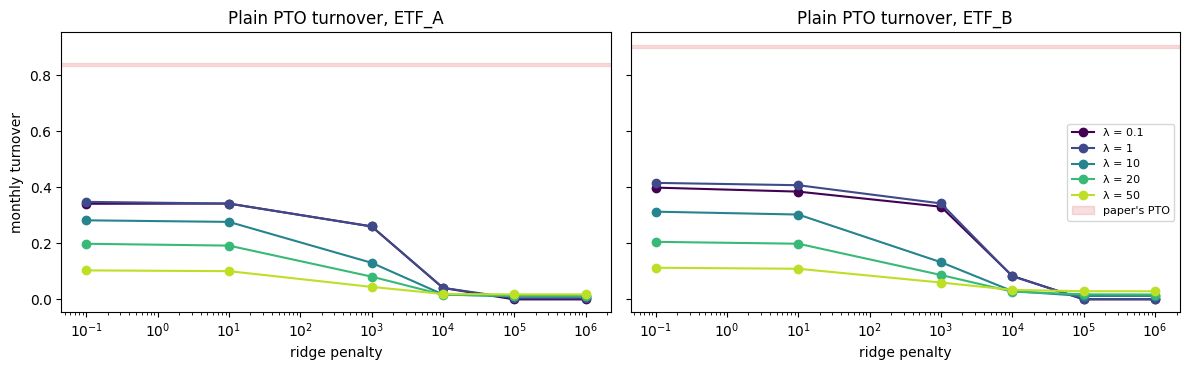

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(config.LAMBDA_GRID)))
fixed = pen[pen["alpha"].map(lambda a: not isinstance(a, str))]
for ax, u in zip(axes, universes):
    for lam, c in zip(config.LAMBDA_GRID, colors):
        s = fixed[(fixed["universe"] == u) & (fixed["lam"] == lam)]
        ax.plot(s["alpha"], s["turnover"], "o-", color=c, label=f"λ = {lam:g}")
    ax.axhspan(paper.loc[u, "turnover"].min(), paper.loc[u, "turnover"].max() + 0.005,
               color="tab:red", alpha=0.15, label="paper's PTO")
    ax.set_xscale("log")
    ax.set_xlabel("ridge penalty")
    ax.set_title(f"Plain PTO turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Criteria and the rule

Criteria 1 and 2 on ETF_A over the first 70 months: turnover at least 0.6 at every λ and changing by less than 0.1 between λ = 0.1 and 50; at least three times classic Markowitz turnover at every λ from 10 up.

In [6]:
rows = []
hi = [l for l in config.LAMBDA_GRID if l >= 10]
for alpha in pen["alpha"].unique():
    a = pen[(pen["universe"] == "ETF_A") & (pen["alpha"] == alpha)].set_index("lam").sort_index()
    change = abs(a.loc[50.0, "turnover"] - a.loc[0.1, "turnover"])
    ratio = a.loc[hi, "turnover"] / a.loc[hi, "markowitz_turnover"]
    rows.append({"alpha": alpha, "turnover range": f"{a['turnover'].min():.2f} to {a['turnover'].max():.2f}",
                 "change λ 0.1 to 50": round(change, 3),
                 "ratio to Markowitz at λ ≥ 10": ", ".join(f"{r:.1f}" for r in ratio),
                 "criterion 1": "PASS" if (a["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
                 "criterion 2": "PASS" if (ratio >= 3).all() else "FAIL",
                 "mean Sharpe": round(a["sharpe"].mean(), 3)})
penalty_criteria = pd.DataFrame(rows).astype({"alpha": str})
print(penalty_criteria.to_string(index=False))

least = penalty_criteria.iloc[0]
print()
if least["criterion 1"] == "PASS" and least["criterion 2"] == "PASS":
    print(f"Rule: the least-penalized model (alpha = {config.PTO_ALPHA_GRID[0]}) passes criteria 1 and 2 "
          "and becomes plain PTO.")
else:
    print(f"Rule: the least-penalized model (alpha = {config.PTO_ALPHA_GRID[0]}) does not pass both criteria. "
          "The replication does not reproduce the paper's PTO turnover.")

              alpha turnover range  change λ 0.1 to 50 ratio to Markowitz at λ ≥ 10 criterion 1 criterion 2  mean Sharpe
                0.1   0.10 to 0.35               0.238                2.2, 2.4, 2.3        FAIL        FAIL        0.215
               10.0   0.10 to 0.34               0.241                2.2, 2.4, 2.2        FAIL        FAIL        0.196
             1000.0   0.04 to 0.26               0.216                1.0, 1.0, 1.0        FAIL        FAIL        0.101
            10000.0   0.02 to 0.04               0.021                0.1, 0.2, 0.4        FAIL        FAIL        0.442
           100000.0   0.00 to 0.02               0.018                0.1, 0.2, 0.4        FAIL        FAIL        0.422
          1000000.0   0.00 to 0.02               0.018                0.1, 0.2, 0.4        FAIL        FAIL        0.427
0.1, month-end rows   0.18 to 0.43               0.246                3.3, 3.9, 3.9        FAIL        PASS       -0.318

Rule: the least-penalized model

## 6. Save

In [7]:
pen.merge(pen_quality, on=["alpha", "universe"]).to_csv(DIRS["reports"] / config.FILES["penalty_diagnostic"],
                                                         index=False)